In [25]:
from DataCollection import load_Dataset
df = load_Dataset()
print("done")

Dataset loaded successfully!
Shape: (2260668, 145)
done


In [51]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
df.sample()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
1356865,NaN,NaN,7500,7500,7500.0,36 months,12.74,251.77,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
'''
Useful features
2
5 to 15
20
23 to 25
27
30 to 34
49,50,56
59 to 63
66 to 71
73,74
76 to 85
89 to 110
'''
old_col = df.columns
df_update1 = df[ 
[old_col[2]] +
list(old_col[5:17])+
[old_col[20]]+
list(old_col[23:26])+
[old_col[27]]+
list(old_col[30:35])+
[old_col[50]]+
[old_col[56]]+
list(old_col[59:64])+
list(old_col[66:72])+
list(old_col[73:75])+
list(old_col[76:86])+
list(old_col[89:111])
]

In [28]:
df_update1.sample()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,pct_tl_nvr_dlq,percent_bc_gt_75,pub_rec_bankruptcies,tax_liens,tot_hi_cred_lim,total_bal_ex_mort,total_bc_limit,total_il_high_credit_limit
1409499,3800,36 months,7.24,117.76,A,A3,Billing Manager,10+ years,MORTGAGE,135000.0,...,0.0,4.0,100.0,14.3,0.0,0.0,317663.0,55770.0,135300.0,32564.0


### 145 features reduced to only 70 imp features

## loan_status is the target variable

In [29]:
df_update1['loan_status'] = df_update1['loan_status'].map({
    'Fully Paid': 0,
    'Charged Off': 1
})
df_update1 = df_update1.dropna(subset=["loan_status"])

In [30]:
for i in range(5):
    print(f"Column_{i+1} : {df_update1.columns[i]}")

Column_1 : loan_amnt
Column_2 : term
Column_3 : int_rate
Column_4 : installment
Column_5 : grade


In [41]:
df_update1["loan_amnt"].unique().max()

np.int64(40000)

In [42]:
df_update1["loan_amnt"].unique().min()

np.int64(500)

### First Trend : loan_amount

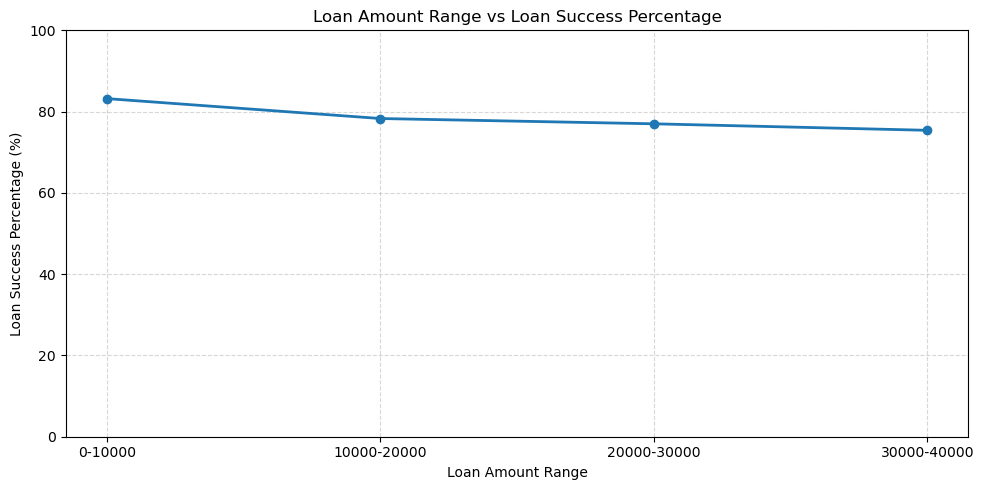


Loan Success Analysis:
      Range  Successful Loan  Unsuccessful Loan  Success percentage
    0-10000           446942              90547                83.2
10000-20000           378790             104793                78.3
20000-30000           157145              47041                77.0
30000-40000            59075              19274                75.4
40000-50000                0                  0                 NaN


In [63]:

def trend1():
    # Trend 1: Loan amount range vs loan success percentage

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import warnings

    warnings.filterwarnings("ignore")

    # Step 1: Create loan amount ranges
    bins = [0, 10000, 20000, 30000, 40000, 50000]

    labels = [
        "0-10000",
        "10000-20000",
        "20000-30000",
        "30000-40000",
        "40000-50000"
    ]

    loan_amount_df = df_update1[
        ["loan_amnt", "loan_status"]
    ].copy()

    loan_amount_df["Range"] = pd.cut(
        loan_amount_df["loan_amnt"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        right=True
    )

    # Step 2: Keep only valid loan statuses and ranges
    filtered_df = loan_amount_df[
        loan_amount_df["loan_status"].isin([0, 1])
        & loan_amount_df["Range"].notna()
    ].copy()

    filtered_df["Range"] = filtered_df["Range"].astype(str)

    # Step 3: Count successful and unsuccessful loans
    counts = (
        filtered_df
        .groupby(["Range", "loan_status"])
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both status columns exist
    for status in [0, 1]:
        if status not in counts.columns:
            counts[status] = 0

    # Ensure all ranges appear in the correct order
    counts = counts.reindex(labels, fill_value=0)

    # Create final DataFrame
    range_df = pd.DataFrame({
        "Range": labels,
        "Successful Loan": counts[0].values,
        "Unsuccessful Loan": counts[1].values
    })

    # Step 4: Calculate success percentage
    total_loans = (
        range_df["Successful Loan"]
        + range_df["Unsuccessful Loan"]
    )

    range_df["Success percentage"] = (
        range_df["Successful Loan"]
        .div(total_loans.replace(0, np.nan))
        .mul(100)
        .round(1)
    )

    # Step 5: Plot the trend
    plt.figure(figsize=(10, 5))

    plt.plot(
        range_df["Range"],
        range_df["Success percentage"],
        marker="o",
        linewidth=2
    )

    plt.xlabel("Loan Amount Range")
    plt.ylabel("Loan Success Percentage (%)")
    plt.title("Loan Amount Range vs Loan Success Percentage")
    plt.ylim(0, 100)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Step 6: Display results
    print("\nLoan Success Analysis:")
    print(range_df.to_string(index=False))


trend1()


### Second trend : term

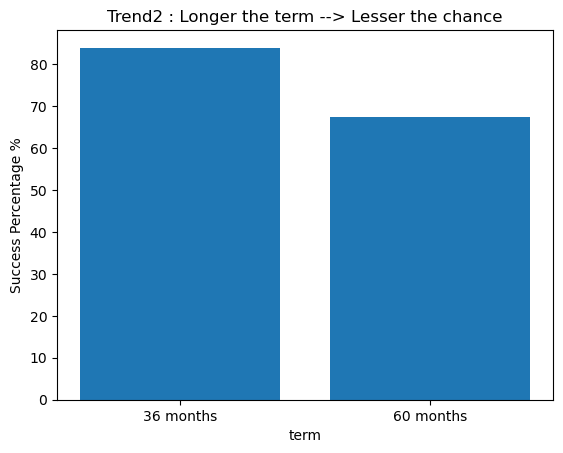

In [61]:
def trend2():
# Second trend : term
    #This trend categories the loan data into two terms, 36 months (3 year) and 60 months (5 year)
    #This determine the probability of loan default on the basis of the term 
    
    list2 = df_update1[["term","loan_status"]].value_counts()
    
    term_column = df_update1["term"].unique()[0:2]
    
    term_df = pd.DataFrame()
    term_df["terms"] = ["36 months" , "60 months"]
    term_df["Total Loans"] = df_update1["term"].value_counts().values
    term_df["Successful Loan"] = [list2[0] , list2[1]]
    term_df["Unsucccessful Loan"] = [list2[2] , list2[3]]
    term_df["Success Percentage"] = round(term_df["Successful Loan"] / term_df["Total Loans"] * 100 , 1) 
    
    x= term_df["terms"]
    y= term_df["Success Percentage"]
    plt.bar(x,y)
    plt.xlabel("term")
    plt.ylabel("Success Percentage %")
    plt.title("Trend2 : Longer the term --> Lesser the chance")
    plt.show()
trend2()

### Third trend : interest rate

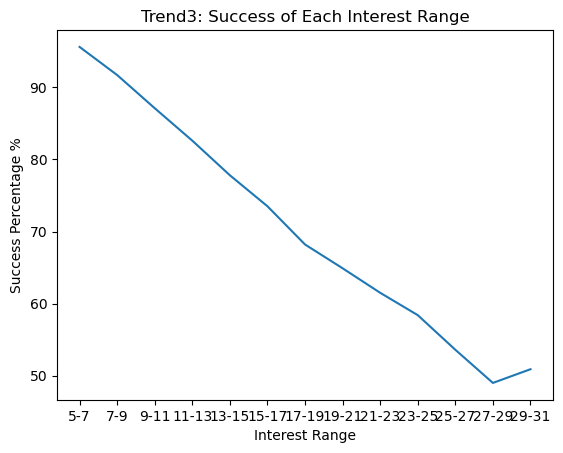

In [60]:
def trend3():
    bins = np.arange(5,32,2)
    labels = [f"{bins[i]}-{bins[i+1]}" for i in range(len(bins)-1)]
    temp_df = pd.DataFrame()
    
    temp_df["Interest_Range"] = pd.cut(
        df_update1["int_rate"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )
    
    temp_df["Interest_Range"].value_counts(sort=False)
    temp_df["loan_status"] = df_update1["loan_status"]
    
    df_int_Range = pd.DataFrame()
    df_int_Range["Interest_Range"] = labels
    df_int_Range["No of Records"] = temp_df["Interest_Range"].value_counts(sort=False).values
    df_int_Range["Approx_Share"] = round(df_int_Range["No of Records"] / temp_df.shape[0] * 100 ,1)
    
    val_list = temp_df[["Interest_Range","loan_status"]].value_counts(sort=False)
    suc_lst=[]
    un_lst=[]
    for i in range(1,len(val_list)+1):
        if i%2==0:
            un_lst.append(val_list[i-1])
        else:
            suc_lst.append(val_list[i-1])
    
    df_int_Range["Successful Loan"]= suc_lst
    df_int_Range["Unsuccessful Loan"] = un_lst
    df_int_Range["Success Percentage"] = round(df_int_Range["Successful Loan"] / df_int_Range["No of Records"] * 100 ,1)
    
    
    x=df_int_Range["Interest_Range"]
    y=df_int_Range["Success Percentage"]
    plt.title("Trend3: Success of Each Interest Range")
    plt.plot(x,y)
    plt.xlabel("Interest Range")
    plt.ylabel("Success Percentage %")
    plt.show()
trend3()

### Fourth Trend : Installment

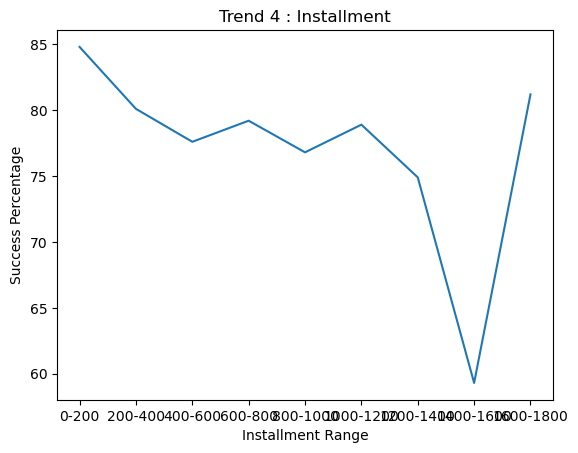

In [59]:
def trend4():
    bins = np.arange(0,1801,200)
    labels = [f"{bins[i]}-{bins[i+1]}" for i in range(len(bins)-1)]
    
    temp_df=pd.DataFrame()
    temp_df["Installment_Range"] = pd.cut(
            df_update1["installment"],
            bins=bins,
            labels=labels,
            include_lowest=True
        )
    temp_df["loan_status"] = df_update1["loan_status"]
    temp_df["Installment_Range"].value_counts(sort=False)
    temp_list = temp_df[["Installment_Range","loan_status"]].value_counts(sort=False).values
    
    
    table = pd.crosstab(
        temp_df["Installment_Range"],
        temp_df["loan_status"]
    ).reindex(columns=[0.0, 1.0], fill_value=0)
    
    suc_lst = table[0.0].tolist()
    un_lst = table[1.0].tolist()
    
        
    # print(labels)
    # print(len(labels))
    # print(f"length of successful list = {len(suc_lst)}\nlength of Unsuccessful list = {len(un_lst)}")
    
    df_installment = pd.DataFrame()
    df_installment["Installment_Range"] = labels
    df_installment["Total Records"] = temp_df["Installment_Range"].value_counts(sort=False).values
    df_installment["Total Share Percentage"] = round( df_installment["Total Records"] / df_installment["Total Records"].sum() *100 ,4)
    df_installment["Successful Records"] = suc_lst
    df_installment["Unsuccessful Records"] = un_lst
    df_installment["Success Percentage"] = round(df_installment["Successful Records"] / df_installment["Total Records"] *100 ,1)
    
    
    x = df_installment["Installment_Range"]
    y = df_installment["Success Percentage"]
    plt.plot(x,y)
    plt.title("Trend 4 : Installment")
    plt.xlabel("Installment Range")
    plt.ylabel("Success Percentage")
    plt.show()
trend4()

### trend5: Grade

In [55]:
df_update1[["grade","loan_status"]].value_counts(sort=False)

grade  loan_status
A      0.0            212477
       1.0             13766
B      0.0            329075
       1.0             51077
C      0.0            286666
       1.0             83262
D      0.0            135839
       1.0             59441
E      0.0             56206
       1.0             35364
F      0.0             17220
       1.0             14263
G      0.0              4469
       1.0              4482
Name: count, dtype: int64

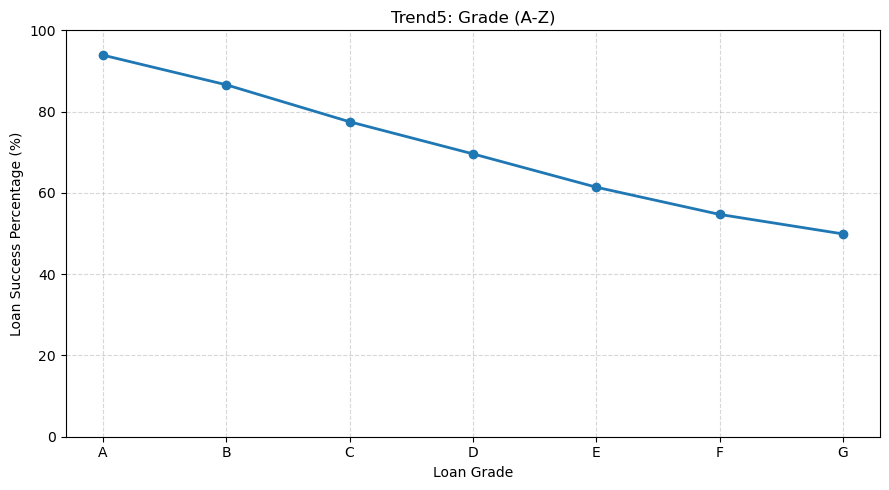


Grade-wise Loan Success Analysis:
Grade  Successful Loan  Unsuccessful Loan  Success percentage
    A           212477              13766                93.9
    B           329075              51077                86.6
    C           286666              83262                77.5
    D           135839              59441                69.6
    E            56206              35364                61.4
    F            17220              14263                54.7
    G             4469               4482                49.9


In [66]:

def trend5():
    # Fifth trend: Grade A to G vs Loan Success Percentage

    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import warnings

    warnings.filterwarnings("ignore")

    # Step 1: Create a DataFrame
    temp_df = df_update1[["grade", "loan_status"]].copy()

    # Step 2: Keep finalized loan statuses
    # 0 = Fully Paid, 1 = Charged Off
    temp_df = temp_df[
        temp_df["loan_status"].isin([0, 1])
    ].dropna(subset=["grade"])

    # Step 3: Count successful and unsuccessful loans by grade
    counts = (
        temp_df.groupby(["grade", "loan_status"])
        .size()
        .unstack(fill_value=0)
    )

    # Ensure both status columns exist
    for status in [0, 1]:
        if status not in counts.columns:
            counts[status] = 0

    # Arrange grades from A to G
    grades = ["A", "B", "C", "D", "E", "F", "G"]
    counts = counts.reindex(grades, fill_value=0)

    # Step 4: Create the final DataFrame
    range_df = pd.DataFrame({
        "Grade": grades,
        "Successful Loan": counts[0].values,
        "Unsuccessful Loan": counts[1].values
    })

    # Step 5: Calculate success percentage
    total_loans = (
        range_df["Successful Loan"]
        + range_df["Unsuccessful Loan"]
    )

    range_df["Success percentage"] = (
        range_df["Successful Loan"]
        .div(total_loans.replace(0, np.nan))
        .mul(100)
        .round(1)
    )

    # Step 6: Plot the trend
    plt.figure(figsize=(9, 5))

    plt.plot(
        range_df["Grade"],
        range_df["Success percentage"].astype(float),
        marker="o",
        linewidth=2
    )

    plt.xlabel("Loan Grade")
    plt.ylabel("Loan Success Percentage (%)")
    plt.title("Trend5: Grade (A-Z)")
    plt.ylim(0, 100)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Step 7: Display results
    print("\nGrade-wise Loan Success Analysis:")
    print(range_df.to_string(index=False))


trend5()


In [65]:
for i in range(5,10):
    print(f"Column_{i+1} : {df_update1.columns[i]}")

Column_6 : sub_grade
Column_7 : emp_title
Column_8 : emp_length
Column_9 : home_ownership
Column_10 : annual_inc
